# Flight Price Data: Overview and Cleaning

**Goal:** load the scraped flight-price dataset, check its structure, data types and completeness, and prepare it for modelling the question *"should a traveller buy a ticket now or wait for a lower price?"*

**Contents**
1. Data loading and feature engineering
2. Labelling and policy evaluation
3. Data quality checks
4. Coverage analysis
5. Initial data summary
6. Route map
7. Price curves for a single flight
8. Ryanair analysis
9. Saving datasets for modelling

## Key findings

- **Waiting usually loses.** Always waiting costs 4 to 18% more than buying now on average, and 48 to 70% of waits end above the purchase price.
- **Perfect hindsight is worth only 2.7 to 5.7%.** The best-possible timing saves little, and the saving grows with the booking horizon (up to 90 days).
- **Savings depend on the airline.** Low-cost carriers (FR, VY, W) show about 6 to 7%; network carriers (LH, KL, AF, BA) show about 2.6 to 3.9%.
- **Data coverage is the bottleneck.** Only 18% of departures have at least one price in every 0 to 90 day window; requiring two or more points per window cuts this to 9%.
- **Prices follow seasonality, region and time of day.** July and August are the most expensive months, Benelux and Britain are the dearest departure regions, and night departures are the cheapest.

*The numbers below come from the saved outputs of the previous run. Re-run the notebook to refresh them.*

In [1]:
import datetime
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

lowess = sm.nonparametric.lowess
warnings.filterwarnings("ignore")

## 1. Data loading and feature engineering

In [32]:
import re
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd

_TIME_RE = re.compile(r"T\d{2}:\d{2}:\d{2}")
MIN_RECORDS = 1          # min price observations per itinerary
WINDOWS = {3:  (3,  0.03, 0.03),   # median gap 1 day
           7:  (5,  0.03, 0.03),   # median gap 1 day, 75th pct 3
           14: (7,  0.05, 0.05),   # median gap 2 days
           30: (10, 0.05, 0.05),   # median gap 2 days
           60: (16, 0.05, 0.05),   # median gap 4 days
           90: (20, 0.05, 0.05)}   # median gap 4 days

DEP_FROM = "2025-07-01"   # first departure date in the analysis (stable scraper period)
DEP_TO = "2026-05-01"     # exclusive upper bound for departure dates

def _norm_id(s):
    return _TIME_RE.sub("", s) if s else s

def _connect(db_path: str) -> sqlite3.Connection:
    con = sqlite3.connect(db_path)
    con.create_function("norm_id", 1, _norm_id, deterministic=True)
    con.execute("PRAGMA cache_size = -200000")   # ~200 MB page cache
    return con

def build_flights(con) -> pd.DataFrame:
    """itin + legs (small tables, ~660k rows) -> one row per itinerary leg."""
    itin = pd.read_sql_query(
        "SELECT itinerary_id, departure_date, region_from, region_to, is_best FROM itin", con)
    legs = pd.read_sql_query(
        """SELECT itinerary_id, airline_code, flight_number, airline_name, aircraft, src, dst, departure_datetime, arrival_datetime, travel_time, emissions
           FROM legs""", con)

    flights = itin.merge(legs, on="itinerary_id", how="inner")
    flights["itinerary_id"] = flights["itinerary_id"].str.replace(_TIME_RE, "", regex=True)
    flights = flights.drop_duplicates(subset=["itinerary_id", "src", "dst"], keep="last")

    for c in ["departure_datetime", "arrival_datetime"]:
        flights[c] = pd.to_datetime(flights[c].str.replace(" ", "T"), format="mixed")
    flights["departure_date"] = pd.to_datetime(flights["departure_date"], errors="coerce")
    return flights

def load_prices(con, valid_ids: set, chunksize=500_000) -> pd.DataFrame:
    """Stream prices; only rows of itineraries that have >= MIN_RECORDS observations survive."""
    # Pass 1: counts computed inside SQLite (no pandas memory)
    counts = pd.read_sql_query(
        """SELECT norm_id(itinerary_id) AS itinerary_id, COUNT(*) AS n
           FROM prices WHERE price > 0 GROUP BY 1 HAVING n >= ?""",
        con, params=(MIN_RECORDS,))
    keep = set(counts["itinerary_id"]) & valid_ids
    print(f"{len(keep):,} itineraries with >= {MIN_RECORDS} price records")

    # Pass 2: stream and keep only those
    parts = []
    for chunk in pd.read_sql_query(
            "SELECT norm_id(itinerary_id) AS itinerary_id, price_datetime, price "
            "FROM prices WHERE price > 0", con, chunksize=chunksize):
        chunk = chunk[chunk["itinerary_id"].isin(keep)]
        chunk["price"] = chunk["price"].astype("float32")
        parts.append(chunk)
    prices = pd.concat(parts, ignore_index=True)
    prices["price_datetime"] = pd.to_datetime(prices["price_datetime"].str.replace(" ", "T"),
                                              format="mixed")
    return prices

def add_features(df: pd.DataFrame) -> pd.DataFrame:
    dep, pr = df["departure_datetime"], df["price_datetime"]
    df["days_to_departure"] = (dep.dt.normalize() - pr.dt.normalize()).dt.days

    # flight number alone ("3600") is ambiguous between airlines: prefix it like in itinerary_id ("A3600")
    df["flight_number"] = df["airline_code"].astype(str) + df["flight_number"].astype(str).str.strip()

    for c in ["airline_code", "flight_number", "airline_name", "aircraft", "src", "dst", "region_from", "region_to"]:
        df[c] = df[c].astype("category")
    return df

def scraper_working_days(d: pd.DataFrame):
    """For every calendar day: did the scraper work? (>= 50% of the rolling median number of itineraries)."""
    per_day = d.groupby("day").size().asfreq("D", fill_value=0)
    typical = per_day.rolling(29, center=True, min_periods=5).median()
    working = (per_day >= 0.5 * typical).to_numpy()
    return working, per_day.index[0], len(per_day)

def price_matrix(d: pd.DataFrame) -> np.ndarray:
    """Row = itinerary (d['code']), column = DTD, value = price (NaN if not scraped that day)."""
    M = np.full((d["code"].max() + 1, max(WINDOWS) + 1), np.nan, dtype="float32")
    M[d["code"], d["dtd"]] = d["price"]
    return M

def window_params(dtd: np.ndarray):
    """From DTD at day t: bucket index, window length N, drop threshold X, rise threshold Y."""
    bucket = np.searchsorted(list(WINDOWS), dtd)
    params = np.array(list(WINDOWS.values()))[bucket]
    return bucket, params[:, 0].astype(int), params[:, 1], params[:, 2]

def walk_windows(M, code, dtd, price, day, N, X, Y, working):
    """Go through the window day by day (k = 1..N days after t).
    Returns for every example:
      first        1 if price fell by X first, -1 if it rose by Y first, 0 if neither
      n_future     how many prices exist inside the window
      days_working how many days of the window the scraper was working"""
    first = np.zeros(len(code), dtype=int)
    n_future = np.zeros(len(code), dtype=int)
    days_working = np.zeros(len(code), dtype=int)
    n_days = len(working)

    for k in range(1, N.max() + 1):
        in_window = (N >= k) & (dtd >= k)                       # day t+k is inside the window
        price_k = M[code, np.maximum(dtd - k, 0)]               # price k days after t (DTD shrinks)
        seen = in_window & ~np.isnan(price_k)

        undecided = first == 0
        first[undecided & seen & (price_k <= price * (1 - X))] = 1
        first[undecided & seen & (price_k >= price * (1 + Y))] = -1

        n_future += seen
        days_working += in_window & working[np.minimum(day + k, n_days - 1)]
    return first, n_future, days_working

def classify(first, n_future, days_working, vanished_for_good, day, Neff, n_days):
    """Assign a status to each labelled observation (see filter_for_cold_start)."""
    return np.select(
        [day + Neff >= n_days,
         (n_future == 0) & vanished_for_good & (days_working >= 0.7 * Neff),
         n_future == 0,
         first == 1,
         first == -1],
        ["drop_end", "vanished", "drop_gap", "wait_drop", "buy_rise"],
        default="buy_flat")

def filter_for_cold_start(df: pd.DataFrame, min_dtd=1, dep_from=DEP_FROM, dep_to=DEP_TO) -> pd.DataFrame:
    """Label price observations of departed flights in [dep_from, dep_to).

    Status values: buy_rise, buy_flat, wait_drop, drop_gap, drop_end, vanished.
    Returns the observations that are kept for modelling (drop_gap and drop_end are removed).
    """
    # one price per itinerary and scrape day, with dtd; keep only dtd covered by WINDOWS
    d = df[["itinerary_id", "price_datetime", "price", "departure_date"]].copy()
    d["day"] = d["price_datetime"].dt.normalize()
    d = d.sort_values("price_datetime").drop_duplicates(["itinerary_id", "day"], keep="last")
    d["dtd"] = (d["departure_date"] - d["day"]).dt.days
    d = d[d["dtd"].between(0, max(WINDOWS))]

    # scraper health: on ALL itineraries, before the period filter
    working, first_day, n_days = scraper_working_days(d)

    # period: already departed, inside the stable-scraper period
    dep = d["departure_date"]
    d = d[(dep >= dep_from) & (dep < dep_to) & (dep <= pd.Timestamp.now().normalize())].copy()

    d["code"], names = pd.factorize(d["itinerary_id"])
    M = price_matrix(d)
    last_dtd = d.groupby("code")["dtd"].transform("min")

    ex = d[d["dtd"] >= min_dtd].copy()
    code, dtd, price = ex["code"].to_numpy(), ex["dtd"].to_numpy(), ex["price"].to_numpy()
    day = (ex["day"] - first_day).dt.days.to_numpy()
    bucket, N, X, Y = window_params(dtd)

    first, n_future, days_working = walk_windows(M, code, dtd, price, day, N, X, Y, working)
    Neff = np.minimum(N, dtd)                       # window cannot run past departure
    # vanished = last observation came early enough that a window could have followed it
    vanished_for_good = (dtd == last_dtd[ex.index].to_numpy()) & (last_dtd[ex.index].to_numpy() > N)

    ex["bucket"] = np.array(list(WINDOWS))[bucket]
    ex["window_N"] = N
    ex["n_future"] = n_future
    ex["status"] = classify(first, n_future, days_working, vanished_for_good, day, Neff, n_days)
    ex["wait"] = (ex["status"] == "wait_drop").astype("int8")

    print(pd.crosstab(ex["bucket"], ex["status"]).to_string(), "\n")
    b3 = ex[ex["bucket"] == 3].copy()
    b3["is_drop_gap"] = b3["status"].eq("drop_gap")
    print(b3.groupby("dtd")["is_drop_gap"].agg(["size", "mean"]).round(3))

    kept = ex[~ex["status"].isin(["drop_gap", "drop_end"])].reset_index(drop=True)

    print(kept.groupby("bucket")["wait"].agg(examples="size", wait_rate="mean").round(3).to_string())
    return kept.drop(columns=["code"])

def prepare(db_path="../scraper/flights.db", cache="flights_clean.parquet", force=False) -> pd.DataFrame:
    """Build the cleaned price table from the raw SQLite database (cached as parquet)."""
    if Path(cache).exists() and not force:
        return pd.read_parquet(cache)
    con = _connect(db_path)
    flights = build_flights(con)
    prices = load_prices(con, set(flights["itinerary_id"]))
    df = prices.merge(flights, on="itinerary_id", how="inner")
    df = add_features(df)

    con.close()

    # Cache the cleaned table for faster reloads
    df.to_parquet(cache, index=False)
    # Also export a SQLite copy for sharing the dataset
    cache_con = sqlite3.connect("flights_clean.sqlite")
    df.to_sql('flights', cache_con, if_exists="replace", index=False, chunksize=200_000)
    cache_con.close()

    return df

In [3]:
# Rebuild the cleaned dataset from the raw database (force=True ignores the cache)
df = prepare(db_path="../scraper/flights.db", cache="flights_clean.parquet", force=True)

1,967,106 itineraries with >= 1 price records


## 2. Labelling and policy evaluation

In [33]:
# Label observations for departures in [DEP_FROM, DEP_TO), at least 2 days before departure
ex = filter_for_cold_start(df, min_dtd=2)

status  buy_flat  buy_rise  drop_gap  vanished  wait_drop
bucket                                                   
3         333696    309337    299030         0      98900
7         456970   1109423    169848     79388     328402
14        366738   1290276     81938     67615     369443
30        928619   2347130    173235     32309     836776
60       1001828   1990261    187068     11673     980956
90       1088843   1161623    186700     14143     941029 

       size   mean
dtd               
2    516233  0.373
3    524730  0.203
        examples  wait_rate
bucket                     
3         741933      0.133
7        1974183      0.166
14       2094072      0.176
30       4144834      0.202
60       3984718      0.246
90       3205638      0.294


**Reading the labels.** About half of observations (51%) are `buy_rise`, meaning the price went up by the threshold first, so buying was right. Another 26% are `buy_flat`, where the price stayed inside the band. `wait_drop` (22%) marks observations where the price fell first. The wait share grows with the booking horizon: 13% at 3 to 7 days, 25% at 60 days and 30% at 90 days.

In [34]:
print(ex["status"].value_counts())

# Wait rate per price bucket, excluding 'vanished' observations
not_vanished = ex[ex["status"] != "vanished"]
print(not_vanished.groupby("bucket")["wait"].agg(examples="size", wait_rate="mean").round(3).to_string())

status
buy_rise     8208050
buy_flat     4176694
wait_drop    3555506
vanished      205128
Name: count, dtype: int64
        examples  wait_rate
bucket                     
3         741933      0.133
7        1894795      0.173
14       2026457      0.182
30       4112525      0.203
60       3973045      0.247
90       3191495      0.295


In [35]:
def thin_every(df, every=4):
    """Keep every `every`-th price observation per itinerary (simulates a lower scrape frequency)."""
    d = df.sort_values(["itinerary_id", "price_datetime"]).copy()
    d["rank"] = d.groupby("itinerary_id").cumcount()
    return d[d["rank"] % every == 0].drop(columns="rank")

# Sensitivity check: does a lower scrape frequency change the wait rate?
full = filter_for_cold_start(df)
thin = filter_for_cold_start(thin_every(df, every=4))

for name, res in [("full", full), ("thinned", thin)]:
    r = res[(res["bucket"] == 60) & (res["status"] != "vanished")]
    print(name, len(r), round(r["wait"].mean(), 3))

status  buy_flat  buy_rise  drop_gap  vanished  wait_drop
bucket                                                   
3         333696    309337    796304         0      98900
7         456970   1109423    169848     79388     328402
14        366738   1290276     81938     67615     369443
30        928619   2347130    173235     32309     836776
60       1001828   1990261    187068     11673     980956
90       1088843   1161623    186700     14143     941029 

       size   mean
dtd               
1    497274  1.000
2    516233  0.373
3    524730  0.203
        examples  wait_rate
bucket                     
3         741933      0.133
7        1974183      0.166
14       2094072      0.176
30       4144834      0.202
60       3984718      0.246
90       3205638      0.294
status  buy_flat  buy_rise  drop_gap  vanished  wait_drop
bucket                                                   
3              0         0    379277         0          0
7          42680    105333    293376     

**Scrape frequency matters.** At the 60-day horizon the wait share is 24.7% with the full data and 18.5% when only every fourth scrape is kept. Sparser scraping therefore makes waiting look less attractive, so the results depend on how often the data was collected.

In [ ]:
# Policy evaluation: 'wait' vs 'buy now' on the labelled observations.
# DEP_FROM / DEP_TO define the departure period, as in filter_for_cold_start.

def price_matrix_for(df):
    """Build the same itinerary x days-to-departure (DTD) price matrix as in filter_for_cold_start.

    Returns
    -------
    M : np.ndarray
        Row = itinerary, column = DTD, value = price (NaN if not scraped on that day).
    code_of : pd.Series
        Maps itinerary_id to its row index in M.
    """
    d = df[["itinerary_id", "price_datetime", "price", "departure_date"]].copy()
    d["day"] = d["price_datetime"].dt.normalize()
    d = d.sort_values("price_datetime").drop_duplicates(["itinerary_id", "day"], keep="last")
    d["dtd"] = (d["departure_date"] - d["day"]).dt.days
    d = d[d["dtd"].between(0, max(WINDOWS))]
    dep = d["departure_date"]
    d = d[(dep >= DEP_FROM) & (dep < DEP_TO) & (dep <= pd.Timestamp.now().normalize())].copy()

    d["code"], names = pd.factorize(d["itinerary_id"])
    M = price_matrix(d)
    code_of = pd.Series(np.arange(len(names)), index=names)
    return M, code_of

def future_prices(M, code, dtd, N):
    """For each observation return (best, last):
    best = lowest price inside its future window (oracle),
    last = last observed price inside its future window."""
    best = np.full(len(code), np.nan, dtype="float32")
    last = np.full(len(code), np.nan, dtype="float32")
    for k in range(1, int(N.max()) + 1):
        ok = (N >= k) & (dtd >= k)
        pk = np.where(ok, M[code, np.maximum(dtd - k, 0)], np.nan).astype("float32")
        best = np.fmin(best, pk)                    # fmin ignores NaN
        last = np.where(np.isnan(pk), last, pk)     # k increases, so the last non-NaN value is the latest
    return best, last

def build_rep(kept, M, code_of):
    """Keep non-vanished rows and add: cur (current price), best, last, has_future and wait."""
    rep = kept[kept["status"] != "vanished"].copy()
    code = code_of.loc[rep["itinerary_id"]].to_numpy()
    dtd = rep["dtd"].to_numpy()
    N = rep["window_N"].to_numpy()
    best, last = future_prices(M, code, dtd, N)
    rep["cur"] = rep["price"].astype("float32")
    rep["best"] = best
    rep["last"] = last
    rep["has_future"] = ~np.isnan(last)
    return rep

def realised_cost(rep, M, code_of):
    """Simulate a 'wait' policy: buy at the first price that crosses the drop threshold X or the rise threshold Y.

    Returns the purchase price and the exit type:
    'drop' (threshold X crossed), 'rise' (threshold Y crossed),
    'end' (no trigger, bought at the last price in the window), 'nofuture' (no later price, bought now).
    """
    code = code_of.loc[rep["itinerary_id"]].to_numpy()
    dtd = rep["dtd"].to_numpy()
    N = rep["window_N"].to_numpy()
    cur = rep["cur"].to_numpy().astype("float64")
    X = rep["bucket"].map({b: v[1] for b, v in WINDOWS.items()}).to_numpy(dtype=float)
    Y = rep["bucket"].map({b: v[2] for b, v in WINDOWS.items()}).to_numpy(dtype=float)

    cost = np.full(len(rep), np.nan)
    kind = np.full(len(rep), "nofuture", dtype=object)
    last = np.full(len(rep), np.nan)

    for k in range(1, int(N.max()) + 1):
        ok = (N >= k) & (dtd >= k)
        pk = np.where(ok, M[code, np.maximum(dtd - k, 0)], np.nan).astype("float64")
        seen = ~np.isnan(pk)
        last = np.where(seen, pk, last)

        undecided = np.isnan(cost)
        drop = undecided & seen & (pk <= cur * (1 - X))
        rise = undecided & seen & (pk >= cur * (1 + Y)) & ~drop
        cost[drop] = pk[drop];  kind[drop] = "drop"
        cost[rise] = pk[rise];  kind[rise] = "rise"

    # no trigger, but prices exist in the window: buy at the last observed price
    end = np.isnan(cost) & ~np.isnan(last)
    cost[end] = last[end]
    kind[end] = "end"

    # no price after the observation: buy now
    none = np.isnan(cost)
    cost[none] = cur[none]

    return cost, kind

def evaluate_policy(rep, cost, pred):
    """Evaluate a policy. pred: 1 = wait, 0 = buy now. Savings are measured against buying now.

    Returns, per bucket: number of observations, mean saving (%), share of 'wait' decisions,
    and the share of waits that ended up costing more than buying now (regret).
    """
    pred = np.asarray(pred).astype(bool)
    cur = rep["cur"].to_numpy().astype("float64")
    paid = np.where(pred, cost, cur)
    saving = (cur - paid) / cur
    out = pd.DataFrame({
        "bucket": rep["bucket"].to_numpy(),
        "saving": saving,
        "waited": pred,
        "regret": pred & (paid > cur),
    })
    g = out.groupby("bucket", observed=True)
    return pd.DataFrame({
        "n": g.size(),
        "mean_saving_%": 100 * g["saving"].mean(),
        "wait_share": g["waited"].mean(),
        "regret_share_of_waits": g["regret"].sum() / g["waited"].sum().replace(0, np.nan),
    }).round(3)

def perfect_timing_saving(rep):
    """Upper bound: buy at the lowest price in the window (not achievable in practice)."""
    cur = rep["cur"].to_numpy()
    best = np.where(rep["has_future"].to_numpy(), np.minimum(rep["best"].to_numpy(), cur), cur)
    s = (cur - best) / cur
    return pd.Series(100 * s, index=rep.index).groupby(rep["bucket"].to_numpy()).mean().round(2)

# ---- Usage ----
M, code_of = price_matrix_for(df)
rep = build_rep(ex, M, code_of)
cost, kind = realised_cost(rep, M, code_of)
rep["kind"] = kind

print("Oracle policy (waits exactly when the wait_drop label is 1):")
print(evaluate_policy(rep, cost, rep["wait"].to_numpy()))

print("\nAlways wait (with a stop-loss on price rises):")
print(evaluate_policy(rep, cost, np.ones(len(rep))))

print("\nExit type counts by bucket:")
print(rep.groupby(["bucket", "kind"], observed=True).size().unstack(fill_value=0))

**What the policies show**
- **Perfect hindsight (oracle):** buying at the lowest price in the window saves 2.7% (3-day horizon) up to 5.7% (90-day horizon). This is an upper bound that no real buyer can reach.
- **Always wait:** loses 4 to 18% on average versus buying now. Stop-losses on rises do not prevent this.
- **Regret:** 48 to 70% of the times a buyer waits, the price ends up higher than buying now. Waiting is a bet that pays off only occasionally.

In [42]:
# Oracle saving per airline (waits exactly when the wait_drop label is 1)
rep["airline_code"] = rep["itinerary_id"].str.extract(r"([A-Z]+)")[0]
print(rep["airline_code"].head(10))

oracle_wait = rep["wait"].to_numpy()
cur = rep["cur"].to_numpy()
rep["oracle_saving"] = (cur - np.where(oracle_wait == 1, cost, cur)) / cur

by_air = rep.groupby("airline_code", observed=True).agg(
    n=("oracle_saving", "size"),
    oracle_saving_pct=("oracle_saving", lambda s: 100 * s.mean()),
    drop_share=("kind", lambda s: (s == "drop").mean()),
    n_itins=("itinerary_id", "nunique"),
)
# Keep only airlines with at least 50 itineraries
by_air = by_air[by_air["n_itins"] >= 50].sort_values("oracle_saving_pct", ascending=False)
print(by_air.round(3).to_string())

0    FR
1    BT
2    LO
3    BT
4    LO
5    LO
6    FR
7    FR
8    FR
9    FR
Name: airline_code, dtype: object
                    n  oracle_saving_pct  drop_share  n_itins
airline_code                                                 
LS              33955              8.760       0.467     2293
F              148572              8.558       0.357    11678
GQ              76787              8.294       0.351     5411
A              264769              7.767       0.314    17841
I               41499              7.658       0.311     2956
RK              30674              7.185       0.393     2108
FR            1257463              6.988       0.384    85881
OE                401              6.731       0.284      110
VY             420394              6.341       0.339    28455
W              248254              6.266       0.402    16920
NK              66759              6.079       0.302     6471
SK            1046111              6.049       0.217    70855
UX             206

**Airline differences.** Oracle savings range from about 1% (ET, only 562 itineraries) to 8.8% (LS, 2,293 itineraries). Among large samples, low-cost carriers such as FR (6.99%, 85,881 itineraries), VY (6.34%) and W (6.27%) show the highest savings. Network carriers such as LH (2.75%), KL (2.65%), AF (3.82%) and BA (3.86%) show the lowest. The share of trigger-driven drops also varies: from 3% (ET) to 47% (LS).

In [44]:
# Oracle savings for different look-ahead windows N, on the same sample for every N (dtd >= 28)
# NOTE: oracle_stats() is not defined in this notebook. Define it before running this cell.
sub = rep[rep["dtd"] >= 28]
rows = []
for N in [3, 7, 14, 21, 28]:
    st = oracle_stats(sub, M, code_of, X=0.05, Y=0.05, N=N)
    rows.append({
        "N_days": N,
        "mean_saving_%": 100 * st["saving"].mean(),
        "trigger_share": st["dropped"].mean(),
        "saving_on_trigger_%": 100 * st.loc[st["dropped"], "saving"].mean(),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

 N_days  mean_saving_%  trigger_share  saving_on_trigger_%
      3          0.319          0.018               17.726
      7          2.113          0.114               18.523
     14          4.289          0.225               19.072
     21          5.259          0.274               19.221
     28          5.601          0.291               19.280


**Look-ahead window.** The savings grow with the window length: 0.3% at 3 days, 2.1% at 7 days, 4.3% at 14 days and 5.6% at 28 days. Longer windows mainly create more chances to trigger a drop (from 2% to 29% of cases). The saving once a trigger fires stays steady at about 18 to 19%.

In [15]:
# kept comes from filter_for_cold_start and still has the status column
kept = ex[~ex["status"].isin(["drop_gap", "drop_end"])].reset_index(drop=True)

ids = kept.groupby("itinerary_id").size().sort_values()
iid = ids.index[len(ids) // 3]   # a typical itinerary, not the extreme

raw = df[df["itinerary_id"] == iid][["price_datetime", "departure_date", "price"]].copy()
raw = raw.sort_values("price_datetime")
raw["day"] = raw["price_datetime"].dt.normalize()
raw["dtd"] = (raw["departure_date"] - raw["day"]).dt.days
raw["gap"] = raw["day"].diff().dt.days
raw["pct"] = raw["price"].pct_change().round(3)

print("departure dates:", raw["departure_date"].nunique())
print(raw[["day", "dtd", "gap", "price", "pct"]].to_string())

lab = kept[kept["itinerary_id"] == iid][["price_datetime", "dtd", "window_N", "n_future", "status"]]
print(lab.to_string())

departure dates: 1
                day  dtd   gap      price    pct
9465240  2025-09-19   87   NaN  83.750000    NaN
10194603 2025-09-27   79   8.0  70.489998 -0.158
10678336 2025-10-01   75   4.0  70.180000 -0.004
11037775 2025-10-05   71   4.0  66.839996 -0.048
11395039 2025-10-09   67   4.0  67.589996  0.011
11979567 2025-10-17   59   8.0  84.120003  0.245
13009358 2025-11-02   43  16.0  77.739998 -0.076
13349111 2025-11-06   39   4.0  85.510002  0.100
13784225 2025-11-21   24  15.0  93.769997  0.097
14008844 2025-11-23   22   2.0  74.190002 -0.209
                     price_datetime  dtd  window_N  n_future     status
9075697  2025-09-19 11:39:49.944380   87        20         4  wait_drop
9791582  2025-09-27 12:54:57.091997   79        20         4  wait_drop
10265558 2025-10-01 11:38:16.926677   75        20         3   buy_rise
10623528 2025-10-05 11:34:12.601904   71        20         2   buy_rise
10955333 2025-10-09 11:37:25.348356   67        20         1   buy_rise
11521549 2

## 3. Data quality checks

In [4]:
print("Data Statistics:")
print(df.columns)
print(df.dtypes)

print(f"Total price records: {len(df):,}")
print(f"Total itineraries: {df['itinerary_id'].nunique():,}")

# Duplicate rows

dup = df[df.duplicated(keep=False)]
print(f"Rows involved in duplication: {len(dup):,}")
print(f"Extra copies (what drop_duplicates would remove): {df.duplicated().sum():,}")
print(dup.sort_values(list(df.columns[:3])).head(20))
# Remove exact duplicate rows
df = df.drop_duplicates(keep="last")

# Missing and zero values
print("Missing values per column:")
print(df.isnull().sum())
print("Zero values per column:")
print((df == 0).sum())

# Price observations per itinerary
print("Price records per itinerary:")
print(df.groupby("itinerary_id").size().describe())

Data Statistics:
Index(['itinerary_id', 'price', 'departure_date', 'region_from', 'region_to',
       'flight_number', 'airline_name', 'operator', 'aircraft', 'src', 'dst',
       'travel_time', 'seat_pitch_type', 'emissions', 'days_to_departure',
       'is_weekend', 'dep_dayofweek', 'dep_month', 'dep_dayofyear',
       'dep_dayofmonth', 'dep_year', 'season', 'dep_hour', 'dep_hour_bin',
       'arr_hour_bin', 'price_hour_bin'],
      dtype='object')
itinerary_id                 object
price                       float32
departure_date       datetime64[ns]
region_from                category
region_to                  category
flight_number              category
airline_name               category
operator                   category
aircraft                   category
src                        category
dst                        category
travel_time                   int64
seat_pitch_type            category
emissions                   float64
days_to_departure             int64
is_we

**Quality summary.** Duplicates and missing values are covered above. The median itinerary has 8 price points, and the distribution is skewed: a quarter of itineraries have 3 or fewer. Thin coverage per itinerary is the main reason the window-based labels have gaps.

## 4. Coverage analysis

In [ ]:
dates = df["departure_date"].dropna().unique()

full_range = pd.date_range(dates.min(), dates.max(), freq="D")
present = full_range.isin(dates)

fig, ax = plt.subplots(figsize=(12, 2))
ax.vlines(full_range[present], 0, 1, color="tab:blue", lw=2, label="present")
ax.vlines(full_range[~present], 0, 1, color="tab:red", lw=2, label="missing")
ax.set_yticks([])
ax.set_title(f"Date coverage: {present.sum()}/{len(full_range)} days present")
ax.legend(loc="upper right", ncol=2)
plt.show()

itin_per_date = df.groupby("departure_date")["itinerary_id"].nunique()
itin_per_date.index = pd.to_datetime(itin_per_date.index)

# full range so missing days show as gaps, not interpolated lines
full_range = pd.date_range(itin_per_date.index.min(), itin_per_date.index.max(), freq="D")
s = itin_per_date.reindex(full_range)

fig, ax = plt.subplots(figsize=(12, 4))
colors = ["tab:red" if d.weekday() == s.groupby(s.index.weekday).mean().idxmin() else "tab:blue"
          for d in s.index]
ax.bar(s.index, s.values, color=colors, width=0.8)
ax.plot(s.index, s.rolling(7, min_periods=4, center=True).mean(),
        color="black", lw=2, label="7-day rolling mean")
ax.set_title("Itineraries per departure date (red = weekday with the lowest average)")
ax.legend()
plt.show()

**Daily volume.** The scraper ramped up from about 300 itineraries a day in May 2025 to about 4,000 by July 2025 and has stayed close to that level since. The dips in late 2025 and January 2026 are periods of lower volume. The labelling step (`scraper_working_days`) excludes such days from the wait decision.

In [ ]:
MAX_DTD = 90

# Share of departures that have a price point at each days_to_departure, per departure month
d_all = df[["itinerary_id", "days_to_departure", "departure_date"]]
d_all = d_all[d_all["days_to_departure"].between(0, MAX_DTD)].drop_duplicates(["itinerary_id", "days_to_departure"]).copy()
d_all["dep_month"] = d_all["departure_date"].dt.to_period("M")

n_per_month = d_all.groupby("dep_month")["itinerary_id"].nunique()
cnt = (d_all.groupby(["dep_month", "days_to_departure"])["itinerary_id"]
            .nunique().unstack(fill_value=0)
            .reindex(columns=range(MAX_DTD + 1), fill_value=0))
share = cnt.div(n_per_month, axis=0)

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(share.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.invert_xaxis()
ax.set_yticks(range(len(share)))
ax.set_yticklabels(share.index.astype(str))
ax.set_xlabel("Days to departure")
ax.set_ylabel("Departure month")
ax.set_title("Share of departures with a price point, by days to departure")
plt.colorbar(im, label="Share of departures with a price point")
plt.tight_layout()
plt.show()

**Monthly coverage.** The heatmap shows, for each departure month, the share of flights that have a price point at each distance from departure (days to departure). Use it to spot months or distances with gaps before reading the policy results.

In [ ]:
# Scraping windows to evaluate (adjust as needed)
EDGES = [0, 4, 8, 15, 31, 46, 61, 91]   # bins: [0-3], [4-7], [8-14], [15-30], [31-45], [46-60], [61-90]
LABELS = ["0-3", "4-7", "8-14", "15-30", "31-45", "46-60", "61-90"]

# Unique (departure, DTD) points
d = df[["itinerary_id", "days_to_departure"]].drop_duplicates()
d = d[d["days_to_departure"].between(0, 90)]
d["win"] = pd.cut(d["days_to_departure"], EDGES, right=False, labels=LABELS)

# Departure x window matrix: number of price points per window
all_ids = df["itinerary_id"].unique()
cnt = (pd.crosstab(d["itinerary_id"], d["win"])
         .reindex(all_ids, fill_value=0)[LABELS])

n_itin, n_pts = len(cnt), int(cnt.values.sum())
print(f"Departures: {n_itin:,}, price points (0-90 DTD): {n_pts:,}\n")

# 1) Bottleneck: share of departures with >= 1 and >= 2 points in each window
cov = pd.DataFrame({"≥1": (cnt >= 1).mean(), "≥2": (cnt >= 2).mean(), "median points": cnt.median()})
print(cov.round(3), "\n")

# 2) Data retained when requiring >= m points in each of the first k windows (counting from 0 days)
rows = []
for k in range(1, len(LABELS) + 1):
    for m in (1, 2, 3):
        ok = (cnt.iloc[:, :k] >= m).all(axis=1)
        rows.append({
            "window": f"0-{EDGES[k]-1}",
            "min points/window": m,
            "departures": int(ok.sum()),
            "% departures": round(100 * ok.mean(), 1),
            "points": int(cnt[ok].values.sum()),
            "% points": round(100 * cnt[ok].values.sum() / n_pts, 1),
        })
res = pd.DataFrame(rows)
print(res.pivot(index="window", columns="min points/window", values=["% departures", "% points"]))

**Coverage by window.** Only 47 to 70% of departures have at least one price point in each window, and 28 to 56% have two or more. Requiring at least one point in every window from 0 to 90 days keeps 18% of departures; requiring two keeps 9%. Keeping only the 0 to 14 day windows with one point each keeps 32% of departures and 59% of price points. This is the trade-off between sample size and coverage that the modelling step has to resolve.

## 5. Initial data summary

**What we have**
- 20,496,381 price records for 1,967,106 itineraries. A typical itinerary has 8 price observations (median; mean 10.4, max 33).
- Departures run from May 2025 onwards. Daily volume rises from about 300 itineraries in May 2025 to about 4,000 a day from July 2025, with a dip in January 2026.
- 11,998 exact duplicate rows were found and removed.

**Missing and zero values**
- `operator` is missing for 82% of rows (16.8M), so it cannot be used.
- `seat_pitch_type` is missing for 0.3% of rows and `aircraft` for 0.1%.
- Zeros in `is_weekend` and `dep_dayofweek` are valid codes (Monday = 0, weekday = 0), and `dep_hour = 0` is midnight. They are not data errors.

**Cleaning done**
- Zero and negative prices are removed during loading (`price > 0`).
- Duplicates are removed.

**Still open**
- Price outliers (up to 15,753 in an earlier check, likely long-haul EU–USA fares).
- Emissions units: values of 40,000 to 220,000 are probably grams per passenger, not kg. Please confirm before reporting them.
- Feature engineering: rolling means over 3, 7 and 14 observations, among others.

## Route map
Flights to and from Vilnius (VNO).

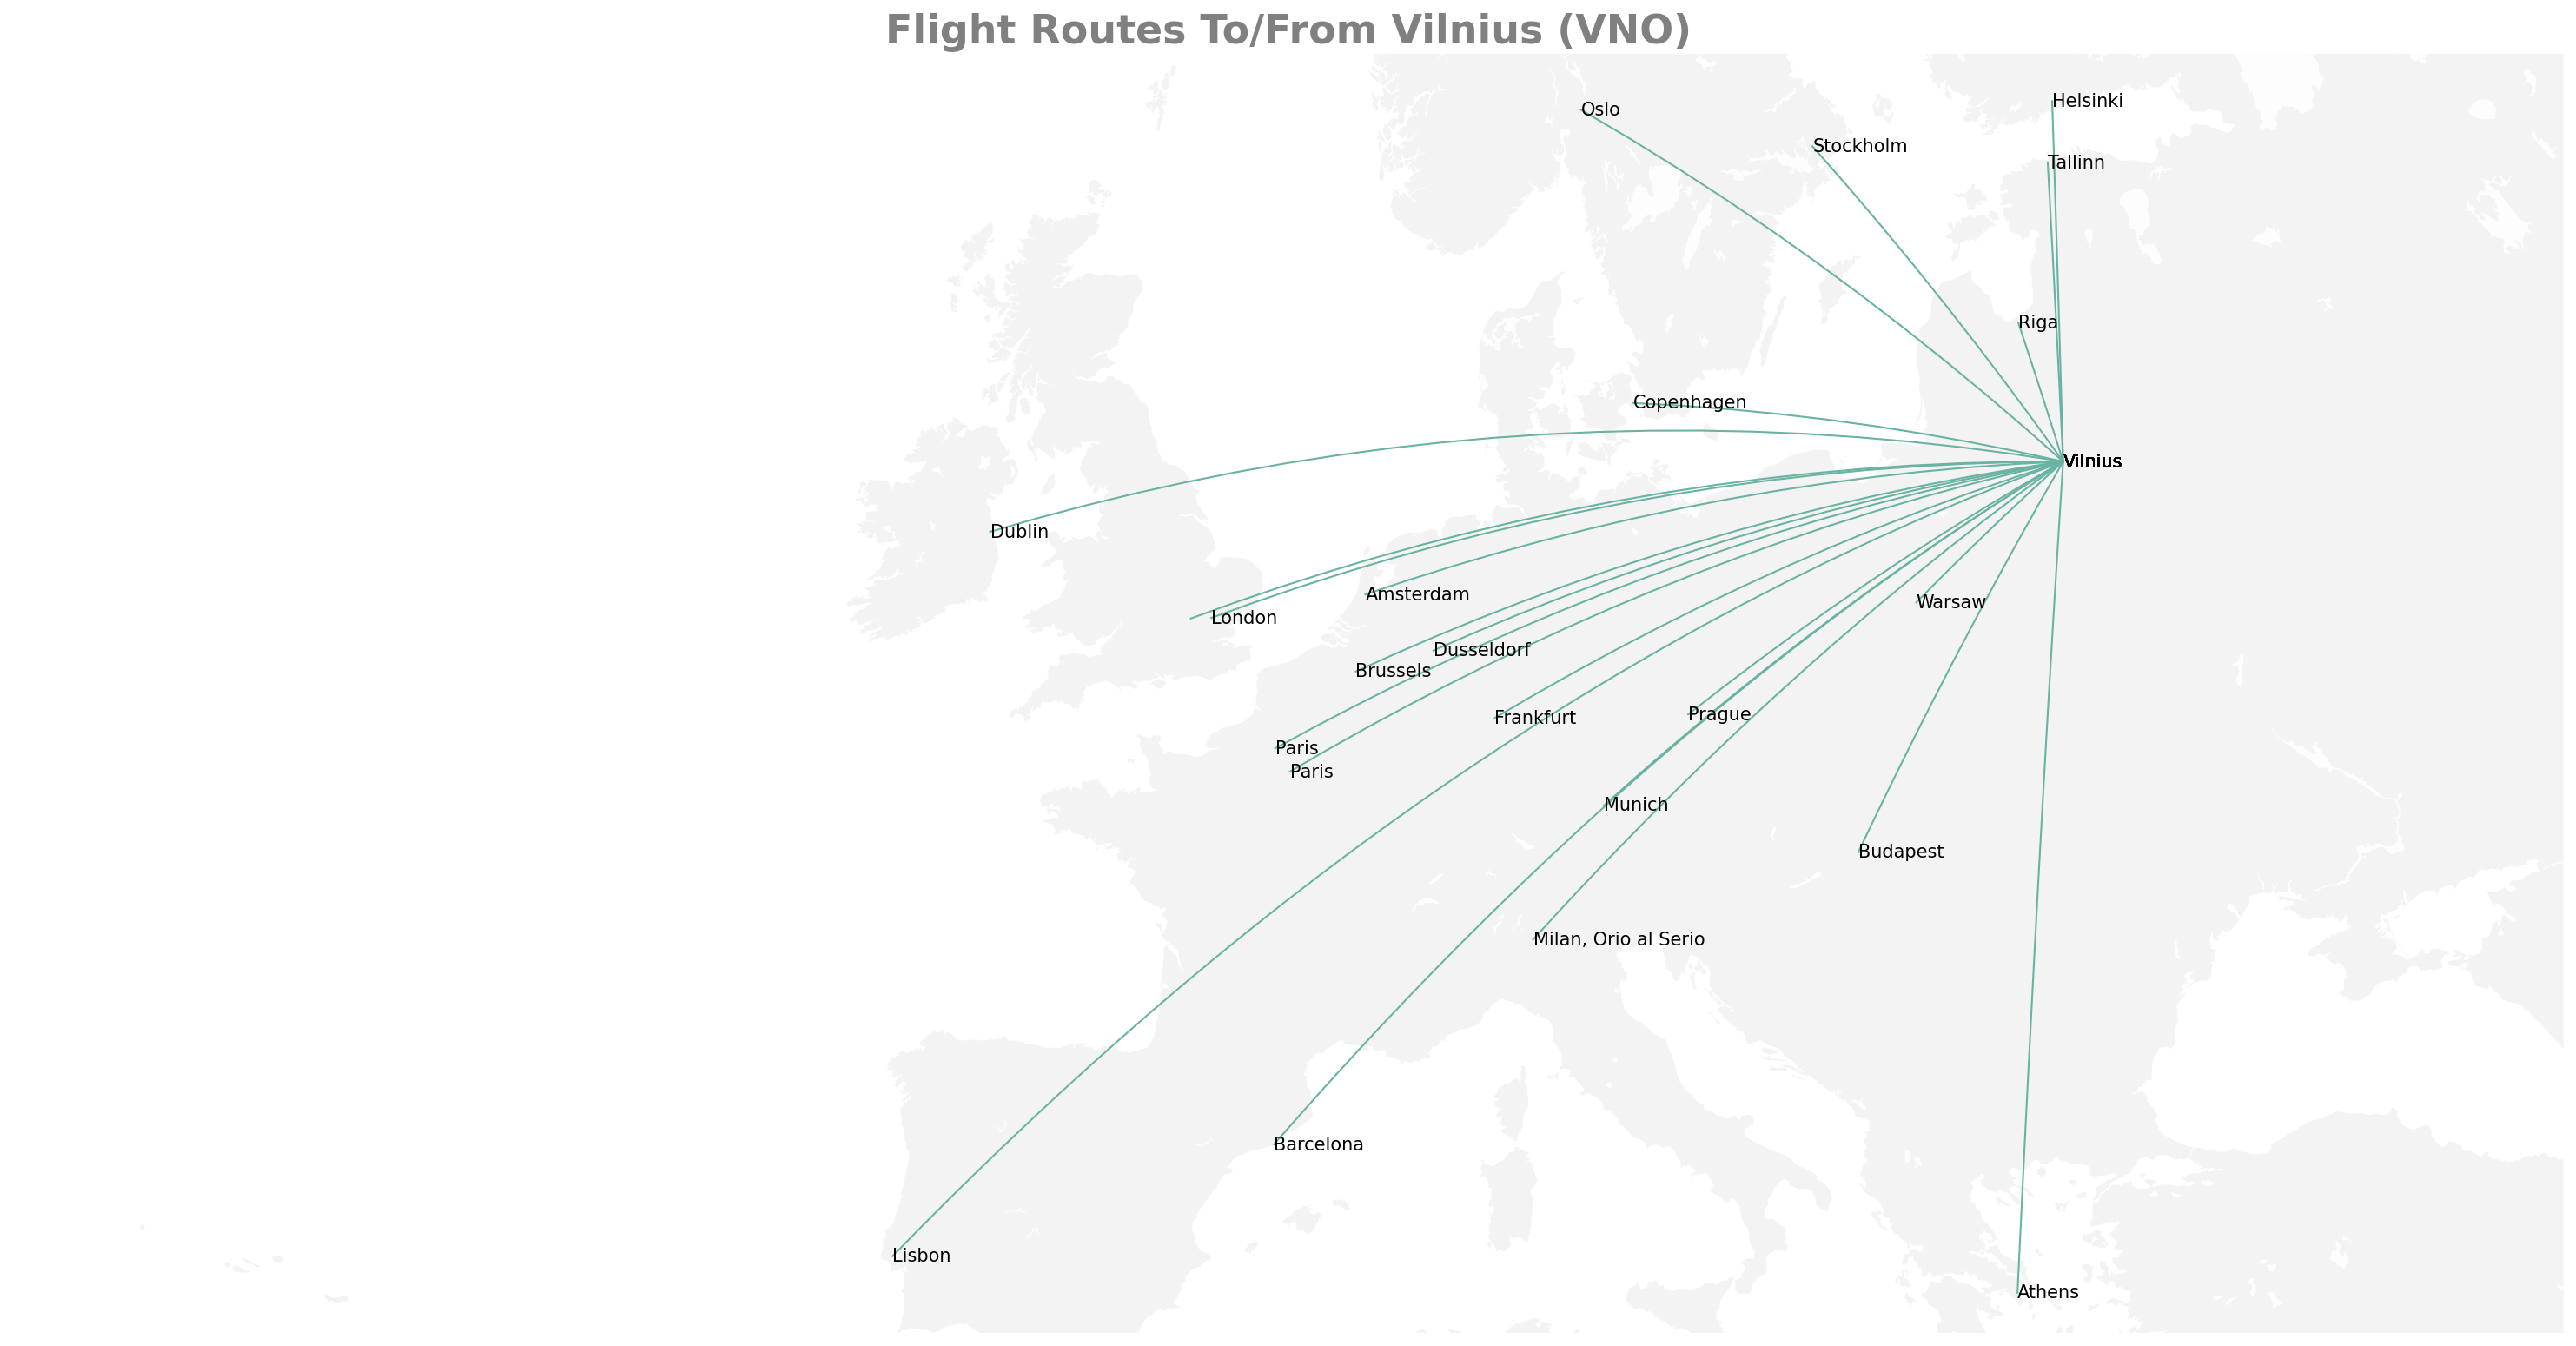

In [ ]:
from mpl_toolkits.basemap import Basemap

ICAO_CSV_PATH = r"F:\pet-projects\google-flight-scraper\demand_scraping\iata-icao.csv"   # airport coordinates lookup

icao_codes_df = pd.read_csv(ICAO_CSV_PATH).dropna().drop_duplicates(subset=["iata"])
coordinates_dict = icao_codes_df.set_index("iata")[["latitude", "longitude", "Ciudad / Location"]].to_dict(orient="index")

# NOTE: merged_df is created in the Ryanair section below; run that cell first.
# Undirected route key, so that A-B and B-A count as the same route
merged_df["sorted_route"] = merged_df.apply(lambda row: "-".join(sorted([row["src"], row["dst"]])), axis=1)
unique_routes = merged_df[["src", "dst", "sorted_route"]].drop_duplicates(subset=["sorted_route"]).reset_index(drop=True)
unique_routes = unique_routes[["src", "dst"]].to_dict(orient="records")

# Keep only routes that start or end in Vilnius (VNO)
unique_routes = [route for route in unique_routes if "VNO" in (route["src"], route["dst"])]

plt.figure(figsize=(20, 12), dpi=150)
plt.title("Flight Routes To/From Vilnius (VNO)",
          fontsize=22,
          fontweight="bold",
          color="gray",
          loc="center")
plt.tight_layout(pad=0)

# Background map
m = Basemap(llcrnrlon=-35,   # lower-left longitude
            llcrnrlat=37,    # lower-left latitude
            urcrnrlon=40,    # upper-right longitude
            urcrnrlat=61,    # upper-right latitude
            resolution="i",
            projection="merc")
m.drawmapboundary(fill_color="white", linewidth=0)
m.fillcontinents(color="#f2f2f2", alpha=0.9)
m.drawcoastlines(linewidth=0.1, color="white")

for route in unique_routes:
    src, dst = route["src"], route["dst"]

    if src in coordinates_dict and dst in coordinates_dict:
        src_coords = coordinates_dict[src]
        dst_coords = coordinates_dict[dst]

        m.drawgreatcircle(src_coords["longitude"], src_coords["latitude"],
                          dst_coords["longitude"], dst_coords["latitude"],
                          linewidth=1, color="#69b3a2")

        # Label both endpoints (London Luton is skipped to avoid clutter)
        if dst_coords["Ciudad / Location"] != "London, Luton":
            plt.annotate(dst_coords["Ciudad / Location"],
                         xy=m(dst_coords["longitude"], dst_coords["latitude"]),
                         verticalalignment="center")
            plt.annotate(src_coords["Ciudad / Location"],
                         xy=m(src_coords["longitude"], src_coords["latitude"]),
                         verticalalignment="center")

**Route map.** Vilnius connects to about 20 cities in the data. Most routes go to Western European hubs (London, Paris, Amsterdam, Brussels, Frankfurt, Munich, Dublin), with a second cluster in the Nordics and Baltics (Riga, Tallinn, Helsinki, Stockholm, Oslo, Copenhagen). A few long routes reach Lisbon and Athens.

## 7. Price curves for a single flight

In [38]:
def filter_itin(data, flight_number=None, date_till=None):
    """Keep itineraries of one flight number and/or departing on or before `date_till`."""
    data = data.copy()
    if flight_number:
        data = data[data["itinerary_id"].str.contains(f"{flight_number}-", na=False)]
    if date_till is not None:
        data["departure_date"] = pd.to_datetime(data["departure_date"], errors="coerce")
        data = data[data["departure_date"] <= pd.Timestamp(date_till)]
    return data

def prices_for_the_route(df, flight_number, flight_date=None, exclude_date=None):
    """Price observations of one flight number, optionally for one departure date or excluding it."""
    out = df[df["flight_number"] == flight_number].copy()
    if flight_date is not None:
        out = out[out["departure_date"] == pd.Timestamp(flight_date)]
    if exclude_date is not None:
        out = out[out["departure_date"] != pd.Timestamp(exclude_date)]
    return out

def mean_curve(df, to_normalize=True, max_days=90, min_count=5):
    """Mean price per days_to_departure, keeping only points with at least `min_count` observations.

    If `to_normalize` is True, prices are divided by the maximum price of each departure date first.
    """
    df = df.copy()
    col = "price"
    if to_normalize:
        df["normalized_price"] = df.groupby("departure_date")["price"].transform(lambda x: x / x.max())
        col = "normalized_price"
    g = (df[df["days_to_departure"] < max_days]
         .groupby("days_to_departure")[col]
         .agg(mean="mean", n="count")
         .reset_index())
    return g[g["n"] >= min_count]

def smooth_LOWESS(df, to_normalize=False, frac=0.13, min_count=5):
    """LOWESS-smoothed mean price curve."""
    g = mean_curve(df, to_normalize, min_count=min_count)
    return lowess(g["mean"], g["days_to_departure"], frac=frac)

def smooth_prices_rolling(df, to_normalize=False, window=3, min_count=5):
    """Centred rolling mean of the mean price curve."""
    g = mean_curve(df, to_normalize, min_count=min_count).sort_values("days_to_departure")
    g["smoothed_price"] = g["mean"].rolling(window, center=True).mean()
    return g[["days_to_departure", "smoothed_price"]].dropna()

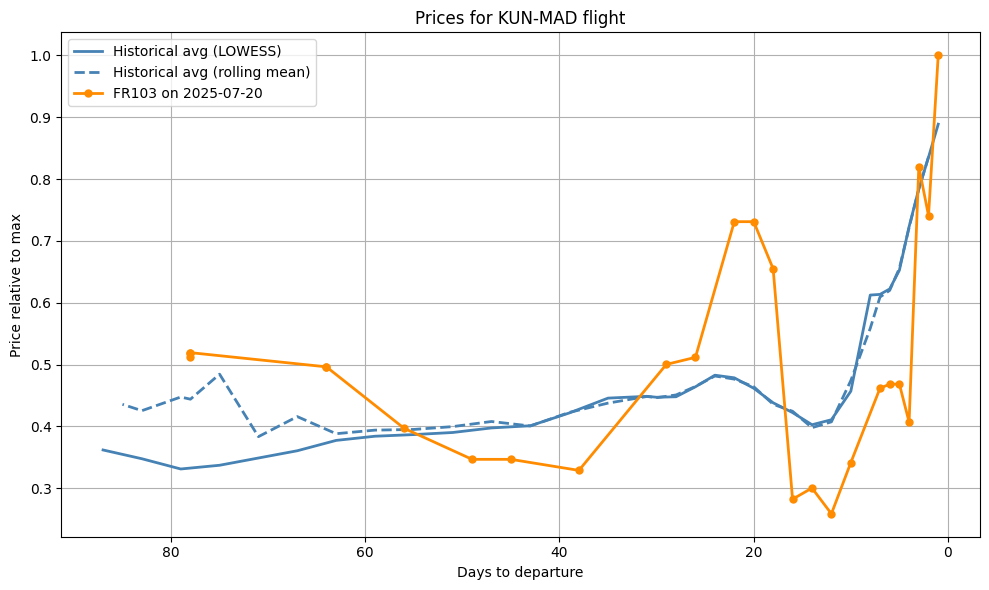

In [39]:
# Compare one departure (TARGET) with the historical average of the same flight number
TARGET = "2025-07-20"

hist = prices_for_the_route(df, "FR103", exclude_date=TARGET)
specific = prices_for_the_route(df, "FR103", flight_date=TARGET)

lo = smooth_LOWESS(hist, to_normalize=True)
roll = smooth_prices_rolling(hist, to_normalize=True, window=3)

specific = specific.sort_values("days_to_departure").copy()
specific["norm"] = specific["price"] / specific["price"].max()

plt.figure(figsize=(10, 6))
plt.plot(lo[:, 0], lo[:, 1], color="steelblue", lw=2, label="Historical avg (LOWESS)")
plt.plot(roll["days_to_departure"], roll["smoothed_price"], color="steelblue",
         ls="--", lw=2, label="Historical avg (rolling mean)")
plt.plot(specific["days_to_departure"], specific["norm"], color="darkorange",
         marker="o", ms=5, lw=2, label=f"FR103 on {TARGET}")
plt.gca().invert_xaxis()
plt.xlabel("Days to departure"); plt.ylabel("Price relative to max")
plt.title("Prices for KUN-MAD flight")
plt.legend(); plt.grid(); plt.tight_layout(); plt.show()

### Insights: FR103 (Kaunas–Madrid)

1. **Price trend.** Prices are relatively stable (100 to 90) from 90 to 60 days before departure, dip to a low (about 80) around 50 days, and then rise sharply (120 to 150) in the last 10 to 5 days. This matches common airline pricing, where prices fall in the middle of the window and spike close to departure.
2. **Booking window.** The dip around 50 days suggests this may be the cheapest time to book KUN–MAD. After sharp rises, prices often fall back (from about 20 to 15 days), which supports the goal of the model: predicting whether it is worth waiting for a cheaper ticket.

## 8. Ryanair analysis

Ryanair itineraries departing within the next 60 days.

In [ ]:
# NOTE: itineraries_df, legs_df, prices_df and merge_dataframes() are not defined in this notebook.
# They must be provided (e.g. loaded from the database) before this cell runs.

def filter_for_airline(df: pd.DataFrame, airline_name: str) -> pd.DataFrame:
    """Return only the rows of one airline.

    :param df: DataFrame containing flight legs.
    :param airline_name: Name of the airline to filter by.
    """
    return df[df["airline_name"] == airline_name]

def plot_price_by_travel_time(df: pd.DataFrame):
    """Scatter plot of price against travel time, with a LOESS trend line."""
    sorted_idx = df["travel_time"].argsort()
    x_sorted = np.array(df["travel_time"])[sorted_idx]
    y_sorted = np.array(df["price"])[sorted_idx]

    loess_result = lowess(y_sorted, x_sorted, frac=0.2)

    plt.figure(figsize=(10, 6))
    plt.scatter(df["travel_time"], df["price"], alpha=0.2, c=df["days_to_departure"], cmap="viridis",
                s=70, linewidth=0.2, edgecolors="none")
    plt.plot(loess_result[:, 0], loess_result[:, 1], color="red", linewidth=2, label="LOESS trend", linestyle="--")
    plt.xlim(50, 250)  # travel time between 50 and 250 minutes
    plt.ylim(0, max(df["price"]) + 20)
    plt.title("Price by Travel Time")
    plt.xlabel("Travel time (minutes)")
    plt.ylabel("Price (€)")
    plt.colorbar(label="Days to departure")
    plt.grid()
    plt.tight_layout()
    plt.show()

filtered_itin_df = filter_itin(itineraries_df, date_till=datetime.datetime.today() + datetime.timedelta(days=60))
ryanair_legs = filter_for_airline(legs_df, "Ryanair")
merged_df = merge_dataframes(filtered_itin_df, ryanair_legs, prices_df)
print(f"Merged DataFrame shape: {merged_df.shape}")

plot_price_by_travel_time(merged_df)

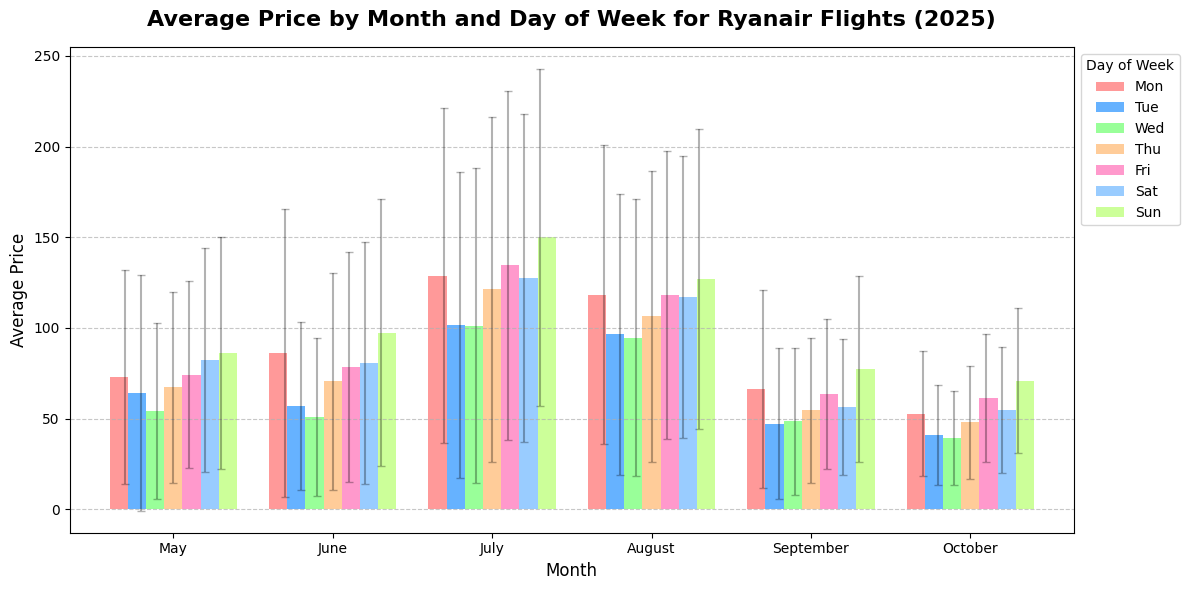

In [13]:
import calendar

data = merged_df.copy()
data["month"] = data["departure_date"].dt.month
data["dayofweek"] = data["departure_date"].dt.dayofweek  # 0 = Monday, 6 = Sunday

monthly_dayofweek_avg = data.groupby(["month", "dayofweek"])["price"].mean().unstack()
monthly_dayofweek_std = data.groupby(["month", "dayofweek"])["price"].std().unstack()

fig, ax = plt.subplots(figsize=(12, 6))
monthly_dayofweek_avg.plot(kind="bar", ax=ax, width=0.8,
                           color=["#FF9999", "#66B2FF", "#99FF99", "#FFCC99", "#FF99CC", "#99CCFF", "#CCFF99"])

# Standard-deviation error bars, offset to line up with each day-of-week bar
for i, month in enumerate(monthly_dayofweek_avg.index):
    for j, day in enumerate(monthly_dayofweek_avg.columns):
        ax.errorbar(i + (j - 3) * 0.1, monthly_dayofweek_avg.iloc[i, j],
                    yerr=monthly_dayofweek_std.iloc[i, j], fmt="none", capsize=3, capthick=1,
                    color="black", alpha=0.3)

ax.set_title("Average Price by Month and Day of Week for Ryanair Flights (2025)", fontsize=16, weight="bold", pad=15)
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Average Price (EUR)", fontsize=12)
ax.set_xticks(range(len(monthly_dayofweek_avg.index)))
ax.set_xticklabels([calendar.month_name[m] for m in monthly_dayofweek_avg.index], rotation=0)
ax.legend(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], title="Day of Week",
          loc="upper left", bbox_to_anchor=(1, 1))
ax.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

**Seasonality.** Average prices are highest in July (about 100 to 150 EUR depending on the weekday), and August is close behind. They fall to about 40 to 80 EUR in September and October. Standard deviations are large in every month (error bars), so the averages hide a wide spread of fares.

> **Note:** the analysis from this point uses `data_transformed` (flights with emissions, region and departure-hour features). It is not created in this notebook and must be built before these cells run.

### Do longer flights emit more CO₂?

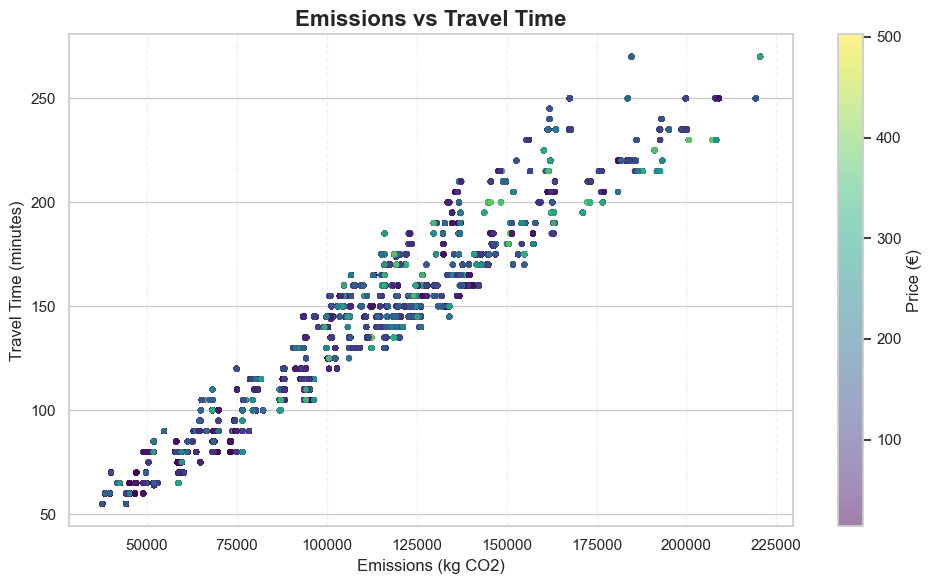

In [39]:
plt.figure(figsize=(10, 6))
plt.scatter(data_transformed['emissions'], data_transformed['travel_time'], alpha=0.5, c=data_transformed['price'], cmap='viridis', s=10)
plt.title("Emissions vs. Travel Time", fontsize=16, weight='bold')
plt.xlabel("Emissions (kg CO₂)")
plt.ylabel("Travel Time (minutes)")
plt.colorbar(label='Price (€)')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()

**Emissions and travel time.** The two are almost linear: longer flights emit more CO₂, which is expected. Price does not show a clear pattern across emissions. Note the units: the axis values of 40,000 to 220,000 are more likely grams per passenger than kilograms, so check this before reporting.

### Which regions have higher flight prices?

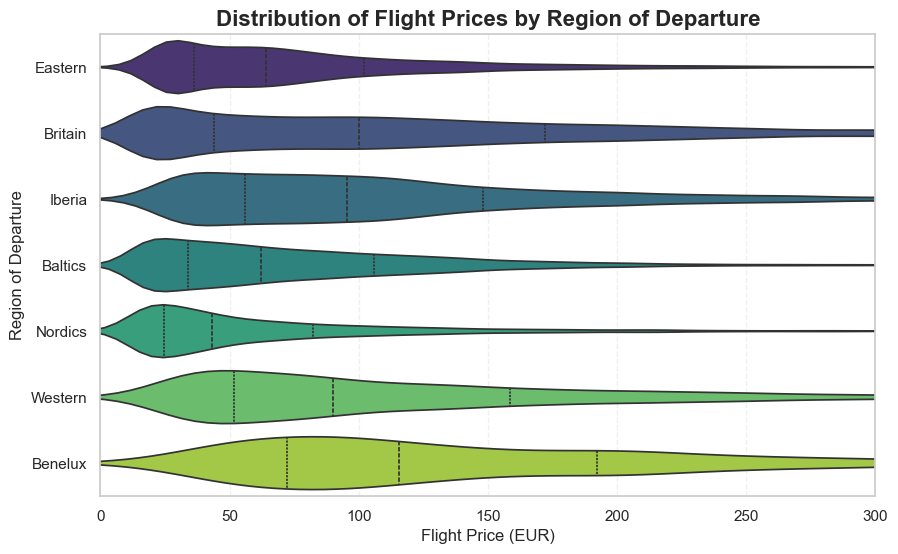

In [43]:
sns.set(style="whitegrid")
plt.figure(figsize=(10, 6))

sns.violinplot(y=data_transformed['region_from'], x=data_transformed['price'],palette='viridis', inner='quartile' )
plt.title('Distribution of Flight Prices by Region of Departure', fontsize=16, weight='bold')
plt.xlabel('Flight Price (EUR)', fontsize=12)
plt.ylabel('Region of Departure', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.xlim(0, 300)
plt.show()

**Prices by departure region.** Medians (approximate, read from the plot) are highest in Benelux (about 115 EUR) and Britain (about 100 EUR), followed by Iberia and Western Europe (about 90 to 95). Baltic and Eastern departures are around 60, and Nordic departures are the cheapest at about 45 EUR.

### Are night and early-morning flights cheaper?

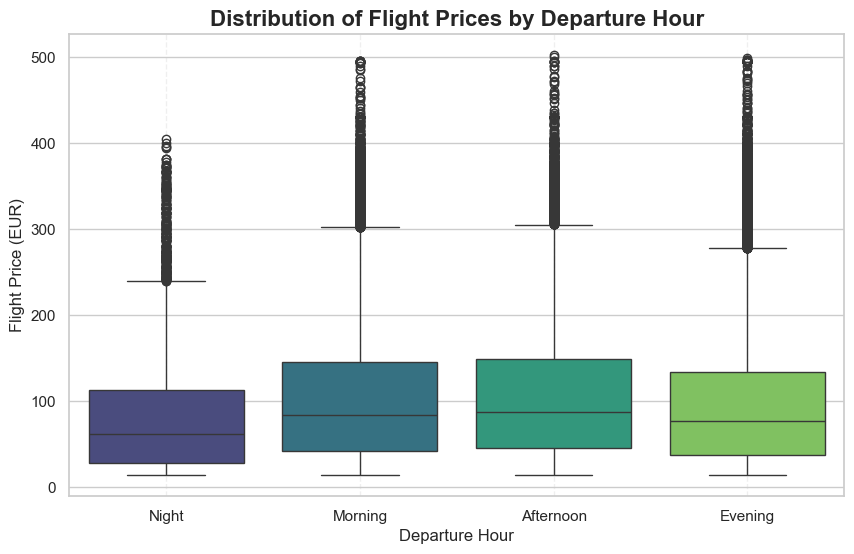

In [49]:
sns.set(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.boxplot(x='dep_hour', y='price', data=data_transformed, palette='viridis')

plt.title('Distribution of Flight Prices by Departure Hour', fontsize=16, weight='bold')
plt.ylabel('Flight Price (EUR)', fontsize=12)
plt.xlabel('Departure Hour', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.show()

**Departure time.** Night departures are cheapest (median about 62 EUR). Morning and afternoon departures have the highest medians (about 84 and 88 EUR), and evening sits in between (about 77 EUR). All groups have many expensive outliers above 300 EUR, which mostly reflect last-minute fares.

### Airline distribution

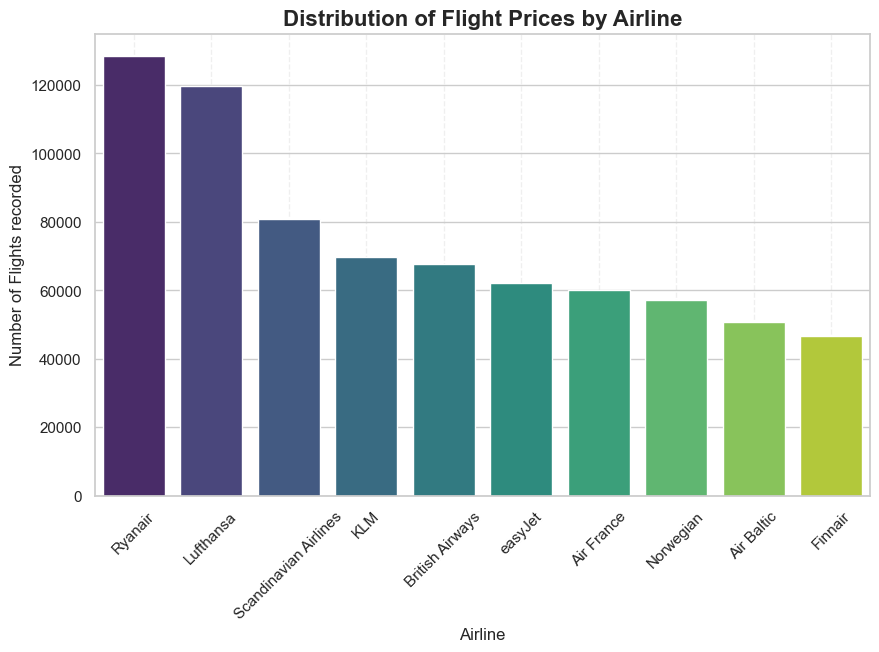

In [17]:
sns.set(style="whitegrid")

plt.figure(figsize=(10, 6))

# Count recorded flights per airline and keep the 10 most frequent
airline_counts = data_transformed['airline_name'].value_counts().reset_index()[:10]

# Show airline distribution
sns.barplot(x='airline_name', y='count', data=airline_counts, palette='viridis')

plt.title('Distribution of Flight Prices by Airline', fontsize=16, weight='bold')
plt.ylabel('Number of Flights recorded', fontsize=12)
plt.xlabel('Airline', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.show()

**Airline coverage.** Ryanair (about 128k records) and Lufthansa (about 120k) make up the largest share of the data, followed by Scandinavian Airlines, KLM and British Airways. The top ten airlines account for most of the records, so results for smaller carriers rest on fewer observations.

## 9. Saving datasets for modelling

In [20]:
TOP_N_AIRLINES = 2   # number of airlines to export

def save_flights_data(data, airlines, folder):
    """Save one CSV per airline into `folder`."""
    for airline in airlines:
        flights = filter_for_airline(data, airline)
        flights.to_csv(f"{folder}/{airline}_data_2.csv", index=False)

Path("airline_data").mkdir(exist_ok=True)
top_airlines = airline_counts["airline_name"][:TOP_N_AIRLINES]
save_flights_data(data_transformed, top_airlines, "airline_data")